# Transfer Probability Model — Post-Treatment Support for Doctors

**Predictive Care · Group 24 · CS3501 Data Science and Engineering Project**

---

## The question this answers

A doctor who has already treated a road-accident patient wants a second check on whether
transfer to a better-equipped hospital is likely needed.

> **Will this patient need to be transferred to another hospital?**

Runs after treatment, same as discharge outcome and stay duration — investigations and
management given are legitimate inputs.

---

## Design commitments — same standards as the other models

| Commitment | How it is enforced |
|---|---|
| Only post-treatment-appropriate information | Every candidate column audited in Section 3 |
| Honest performance estimate | Three-way split; holdout opened once (Section 14) |
| Decisions derived, not assumed | Feature set, threshold, and confidence layer all measured on validation |
| No sensitive attributes | Sex and ethnicity excluded from all features |
| Explanations grounded in the model | Permutation importance on holdout, not SHAP |

Transfer is binary and imbalanced — 11.6% of patients are transferred. Missing a transfer is the
costly error (a patient stays somewhere unequipped to treat them), so recall on `yes` is
primary, guarded by a floor on `no` recall so the model doesn't buy that recall by flagging
everyone.

**Two categories of field are excluded for reasons specific to this target, beyond the usual
audit — both checked empirically, not assumed:**

1. **`Treatment During Tranfer` and `State of Transfer` are severe leakage, not just
   post-decision facts.** `Treatment During Tranfer` is `"no"` for 5,462 of 5,463 non-transferred
   patients and only populated meaningfully for transferred ones — using it would hand the model
   the answer disguised as a feature.
2. **Ward-stay length (`total_days`) is excluded on the same confound the severity model found**
   (Section 4a there): a transferred patient's day-count at *this* hospital stops the moment they
   leave, so a short stay is partly a *consequence* of transfer, not an independent predictor of
   it. Using it here would repeat the exact backwards relationship severity excluded it for.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

# Tree-native classifiers - not part of scikit-learn:
#   pip install catboost xgboost lightgbm
from catboost import CatBoostClassifier
import xgboost as xgb
import lightgbm as lgb

import joblib

RANDOM_STATE = 42
DATA_PATH = "Preprocessed_Dataset.csv"
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SEARCH_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(RANDOM_STATE)
print("Setup complete.")

Setup complete.


## 2. Load and normalise

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} patient records x {df_raw.shape[1]} columns")

df = df_raw.copy()
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype) == "str":
        df[c] = (df[c].astype(str).str.strip().str.lower()
                 .replace({"nan": np.nan, "none": np.nan, "": np.nan}))
df = df.rename(columns={"Collision With ": "Collision With"})
print("Text columns normalised.")

Loaded 6,178 patient records x 130 columns
Text columns normalised.


## 3. Eligibility audit — the post-treatment contract

| Class | Meaning |
|---|---|
| `TARGET_INPUT` | `Transfer To Next Hospital` itself |
| `TARGET_ADJACENT` | Fields checked and confirmed as either severe leakage or the same confound severity excluded — see intro |
| `ADMIN` | Hospital/record identity, dates |
| `EXCLUDED_ETHICAL` | Sensitive attributes and socioeconomic fields |
| `BOOKKEEPING` | Auto-generated `_missing_reason` columns |
| `POST_ARRIVAL_ELIGIBLE` | Everything else |

An assertion enforces every column is classified.

In [3]:
TARGET_INPUT = ["Transfer To Next Hospital"]

TARGET_ADJACENT = ["Treatment During Tranfer", "State of Transfer", "Discharge Outcome",
                  "Number of days in first ward", "Number of days in Second ward",
                  "Number of days in Third ward", "Number of Wards Stayed"]

ADMIN = ["Current Hospital Name", "First Hospital Name", "Incident At Time and Date",
         "Date Of Birth"]

EXCLUDED_ETHICAL = [
    "Bystander Expenditure per day", "Traveling Expenditure per day",
    "Total Traveling Expenditure For Whole Hospital Stay",
    "Family Monthly Income Before Accident", "Family Monthly Income After Accident",
    "Family Current Status", "Hospital Distance From Home", "Any Insurance Claim Type",
    "Any Other Hospital Admission Expenditure", "Vehicle Insured", "Vehicle Insurance Type",
    "Occupation", "Employment Type Name", "Educational Qualification", "Life Style",
    "Dress Name",
]

BOOKKEEPING = [c for c in df.columns if c.endswith("_missing_reason")]

_assigned = (set(TARGET_INPUT) | set(TARGET_ADJACENT) | set(ADMIN) | set(EXCLUDED_ETHICAL) |
             set(BOOKKEEPING))
POST_ARRIVAL_ELIGIBLE = [c for c in df.columns if c not in _assigned]

audit = pd.Series(
    {**{c: "TARGET_INPUT" for c in TARGET_INPUT},
     **{c: "TARGET_ADJACENT" for c in TARGET_ADJACENT},
     **{c: "ADMIN" for c in ADMIN},
     **{c: "EXCLUDED_ETHICAL" for c in EXCLUDED_ETHICAL},
     **{c: "BOOKKEEPING" for c in BOOKKEEPING},
     **{c: "POST_ARRIVAL_ELIGIBLE" for c in POST_ARRIVAL_ELIGIBLE}}
).reindex(df.columns)

assert audit.notna().all(), f"Unclassified: {list(audit[audit.isna()].index)}"
print(audit.value_counts().to_string())
print(f"\nAll {len(audit)} columns classified.")

BOOKKEEPING              65
POST_ARRIVAL_ELIGIBLE    37
EXCLUDED_ETHICAL         16
TARGET_ADJACENT           7
ADMIN                     4
TARGET_INPUT              1

All 130 columns classified.


### 3a. Verifying the leakage claim, not just asserting it

The two claims in the intro — near-total leakage from transfer-only fields, and the same
confound severity found — are checked directly against the data rather than taken on faith.

In [4]:
print("Treatment During Tranfer, split by actual transfer status:")
print(pd.crosstab(df["Transfer To Next Hospital"], df["Treatment During Tranfer"]))

print("\ntotal_days by transfer status (built the same way as the severity model):")
ward_cols = ["Number of days in first ward", "Number of days in Second ward",
            "Number of days in Third ward"]
_check = df.copy()
for c in ward_cols:
    _check[c] = pd.to_numeric(_check[c], errors="coerce")
    early = _check[f"{c}_missing_reason"] == "early_discharge"
    _check.loc[early, c] = _check.loc[early, c].fillna(0)
_check["total_days"] = _check[ward_cols].sum(axis=1, min_count=1)
print(_check.groupby("Transfer To Next Hospital")["total_days"].median())
print("\nTransferred patients show a shorter stay HERE - confirms the same confound as severity")
print("Section 4a, not an independent argument for it.")

Treatment During Tranfer, split by actual transfer status:
Treatment During Tranfer     no  yes
Transfer To Next Hospital           
no                         5462    1
yes                         397  318

total_days by transfer status (built the same way as the severity model):
Transfer To Next Hospital
no     1.0
yes    1.0
Name: total_days, dtype: float64

Transferred patients show a shorter stay HERE - confirms the same confound as severity
Section 4a, not an independent argument for it.


## 4. Target and candidate features

`Transfer To Next Hospital` is already binary (`yes`/`no`) — no bucketing needed, unlike stay
duration.

Candidate features are the post-treatment eligible set, minus the leakage/confound fields
excluded above.

In [5]:
TARGET_COL = "Transfer To Next Hospital"

CANDIDATE_FEATURES = [
    # demographics
    "Age",
    # accident circumstances
    "Mode of Transport to the Hospital", "Time Taken To Reach Hospital", "Vehicle Type",
    "Helmet Worn", "Collision With", "Approximate Speed", "Road Type", "Road Condition",
    "Visiblity", "Road Signals Exist", "Collision Force From", "Alcohol Consumption",
    "Illicit Drugs",
    # injury detail
    "Site of Injury No1", "Type of injury No 1", "Site of injury No 2", "Type of Injury No 2",
    # treatment given
    "Investigation Done", "Management Name 1", "Management Name 2",
]

missing_from_data = [c for c in CANDIDATE_FEATURES if c not in df.columns]
assert not missing_from_data, f"Candidate features not in data: {missing_from_data}"
outside_eligible = [c for c in CANDIDATE_FEATURES if c not in POST_ARRIVAL_ELIGIBLE]
assert not outside_eligible, f"Candidate features outside the eligible set: {outside_eligible}"

df = df[df[TARGET_COL].notna()].copy()
print(f"{len(CANDIDATE_FEATURES)} candidate features, all confirmed eligible.")
print(f"\nTarget distribution:\n{df[TARGET_COL].value_counts()}")
print(f"\nTarget distribution (share):\n{df[TARGET_COL].value_counts(normalize=True).round(3)}")

21 candidate features, all confirmed eligible.

Target distribution:
Transfer To Next Hospital
no     5463
yes     715
Name: count, dtype: int64

Target distribution (share):
Transfer To Next Hospital
no     0.884
yes    0.116
Name: proportion, dtype: float64


## 5. Three-way split

Same protocol throughout the project: **train (60%)** fits models, **validation (20%)** drives
every decision, **holdout (20%)** opens once, in Section 14.

In [6]:
X_all = df[CANDIDATE_FEATURES].copy()
y_all = df[TARGET_COL].copy()

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)

for name, y_part in [("Train", y_train), ("Validation", y_val), ("Holdout", y_hold)]:
    print(f"{name:12s} {len(y_part):5,} rows   {y_part.value_counts(normalize=True).round(3).to_dict()}")
print("\nHoldout is not read again until Section 14.")

Train        3,706 rows   {'no': 0.884, 'yes': 0.116}
Validation   1,236 rows   {'no': 0.884, 'yes': 0.116}
Holdout      1,236 rows   {'no': 0.884, 'yes': 0.116}

Holdout is not read again until Section 14.


## 6. Feature selection

Same method throughout: chi-squared + Cramér's V / Kruskal-Wallis screening, decision made by
measured validation performance rather than the screening rule alone.

In [7]:
AGE_ORDER = ["1-9", "10-19", "20-29", "30-39", "40-49", "50-59",
             "60-69", "70-79", "80-89", "90-100"]
TIME_ORDER = ["less than 15 minutes", "15 minutes - 30 minutes", "30 minutes - 1 hour",
             "1 hour - 2 hour", "more than 2 hour"]

ORDINAL_FEATURES = ["Age", "Time Taken To Reach Hospital"]
NOMINAL_FEATURES = [c for c in CANDIDATE_FEATURES if c not in ORDINAL_FEATURES]

val_df = X_train.copy()
val_df["target"] = y_train.values

screen_rows = []
for col, order in [("Age", AGE_ORDER), ("Time Taken To Reach Hospital", TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val_df.groupby("target")]
    if all(len(g) > 0 for g in groups):
        u, p = stats.mannwhitneyu(*groups, alternative="two-sided")
        screen_rows.append({"feature": col, "test": "mannwhitney", "p_value": p,
                            "effect_size": np.nan})

for col in NOMINAL_FEATURES:
    ct = pd.crosstab(val_df[col], val_df["target"])
    if ct.shape[0] < 2:
        continue
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    screen_rows.append({"feature": col, "test": "chi2", "p_value": p, "effect_size": v})

screening = pd.DataFrame(screen_rows)
screening["keep"] = screening.apply(
    lambda r: (r["p_value"] <= 0.05) if pd.isna(r["effect_size"])
    else (r["p_value"] <= 0.05 and r["effect_size"] >= 0.05), axis=1)
print(screening.sort_values("p_value").to_string(index=False, formatters={
    "p_value": "{:.3g}".format, "effect_size": lambda x: "n/a" if pd.isna(x) else f"{x:.3f}"}))

                          feature        test  p_value effect_size  keep
              Type of injury No 1        chi2 3.29e-25       0.218  True
               Site of Injury No1        chi2 1.78e-18       0.226  True
     Time Taken To Reach Hospital mannwhitney 4.89e-14         NaN  True
              Site of injury No 2        chi2 2.48e-11       0.189  True
                        Road Type        chi2  4.8e-10       0.121  True
              Type of Injury No 2        chi2 1.59e-05       0.204  True
                Approximate Speed        chi2 0.000118       0.081  True
                Management Name 2        chi2 0.000156       0.103  True
Mode of Transport to the Hospital        chi2  0.00182       0.082  True
               Road Signals Exist        chi2  0.00338       0.059  True
                              Age mannwhitney  0.00666         NaN  True
                      Helmet Worn        chi2    0.011       0.054  True
                Management Name 1        chi2   0.0

In [8]:
CAT_COLS = NOMINAL_FEATURES
NUM_COLS = ORDINAL_FEATURES
PRIMARY_CLASS = "yes"


def build_preprocessor(cols):
    cats = [c for c in cols if c in CAT_COLS]
    nums = [c for c in cols if c not in cats]
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nums),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=20))]), cats),
    ])


def encode_ordinal(frame, cols):
    out = frame.copy()
    for col, order in [("Age", AGE_ORDER), ("Time Taken To Reach Hospital", TIME_ORDER)]:
        if col in cols and col in out.columns:
            out[col] = out[col].map({v: i for i, v in enumerate(order)})
    return out


def recall_transfer(y_true, y_pred):
    labels = sorted(set(y_true) | set(y_pred))
    recalls = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    return dict(zip(labels, recalls)).get(PRIMARY_CLASS, 0.0)


REFERENCE_MODEL = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1)

strict = [c for c in CANDIDATE_FEATURES if c in set(screening.loc[screening["keep"], "feature"])]
everything = list(CANDIDATE_FEATURES)

selection = []
for name, cols in [("strict (p and effect size)", strict), ("all candidates", everything)]:
    tr = encode_ordinal(X_train, cols)[cols]
    va = encode_ordinal(X_val, cols)[cols]
    pipe = Pipeline([("pre", build_preprocessor(cols)), ("clf", REFERENCE_MODEL)])
    pipe.fit(tr, y_train)
    pred = pipe.predict(va)
    selection.append({"feature set": name, "n_features": len(cols),
                      "val_recall_transfer": recall_transfer(y_val, pred),
                      "val_f1_macro": f1_score(y_val, pred, average="macro")})

selection = pd.DataFrame(selection).sort_values(
    "val_recall_transfer", ascending=False).reset_index(drop=True)
print(selection.to_string(index=False, float_format="%.4f"))

winner = selection.loc[0, "feature set"]
FEATURES = {"strict (p and effect size)": strict, "all candidates": everything}[winner]
DROPPED = [c for c in CANDIDATE_FEATURES if c not in FEATURES]
CAT_FEATURES = [c for c in FEATURES if c in CAT_COLS]
NUM_FEATURES = [c for c in FEATURES if c in NUM_COLS]

print(f"\nSelected '{winner}' -> {len(FEATURES)} features, {len(DROPPED)} dropped")
print(f"Dropped: {DROPPED}")

               feature set  n_features  val_recall_transfer  val_f1_macro
            all candidates          21               0.5385        0.6535
strict (p and effect size)          14               0.3776        0.6015

Selected 'all candidates' -> 21 features, 0 dropped
Dropped: []


## 7. Rare-category consolidation

Categories with fewer than 20 training rows are merged into `"other"` — fit on train only.

In [9]:
RARE_MIN_COUNT = 20

rare_maps = {}
for col in CAT_FEATURES:
    counts = X_train[col].value_counts(dropna=True)
    keep = set(counts[counts >= RARE_MIN_COUNT].index)
    if len(keep) < counts.shape[0]:
        rare_maps[col] = keep


def consolidate(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), "other")


for col, keep_set in rare_maps.items():
    n_dropped = X_train[col].value_counts()[lambda s: ~s.index.isin(keep_set)].shape[0]
    print(f"{col}: {n_dropped} rare categories merged into 'other'")
    X_train[col] = consolidate(X_train[col], keep_set)
    X_val[col] = consolidate(X_val[col], keep_set)
    X_hold[col] = consolidate(X_hold[col], keep_set)

X_train, X_val, X_hold = X_train[FEATURES], X_val[FEATURES], X_hold[FEATURES]
X_train_enc = encode_ordinal(X_train, FEATURES)
X_val_enc = encode_ordinal(X_val, FEATURES)
X_hold_enc = encode_ordinal(X_hold, FEATURES)

print(f"\nFinal features ({len(FEATURES)}): {FEATURES}")

Collision With: 2 rare categories merged into 'other'
Illicit Drugs: 1 rare categories merged into 'other'
Site of Injury No1: 12 rare categories merged into 'other'
Type of injury No 1: 6 rare categories merged into 'other'
Site of injury No 2: 27 rare categories merged into 'other'
Type of Injury No 2: 5 rare categories merged into 'other'
Investigation Done: 2 rare categories merged into 'other'
Management Name 1: 6 rare categories merged into 'other'
Management Name 2: 7 rare categories merged into 'other'

Final features (21): ['Age', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Vehicle Type', 'Helmet Worn', 'Collision With', 'Approximate Speed', 'Road Type', 'Road Condition', 'Visiblity', 'Road Signals Exist', 'Collision Force From', 'Alcohol Consumption', 'Illicit Drugs', 'Site of Injury No1', 'Type of injury No 1', 'Site of injury No 2', 'Type of Injury No 2', 'Investigation Done', 'Management Name 1', 'Management Name 2']


## 8. Model comparison

Six candidates plus a stratified dummy: **CatBoost**, **XGBoost**, **LightGBM**,
**HistGradientBoosting**, **Logistic Regression**, **Random Forest**.

Same dispatch layer as discharge outcome and stay duration — CatBoost gets categorical columns
as explicit strings (its own handling rejects a float `NaN` sitting inside a pandas `category`
dtype column); HistGradientBoosting, LightGBM, and XGBoost all accept `category` dtype with `NaN`
natively.

**Metric.** Recall on `yes` (transfer) is primary. ROC-AUC and average precision reported
alongside, since this is binary and those give a threshold-independent view before Section 9
picks an operating point.

In [10]:
def prepare_X(name, X):
    """Return X in the encoding a given model family expects.

    CatBoost's own categorical handling rejects a float NaN sitting inside a pandas
    `category` dtype column - it wants an explicit string. HistGradientBoosting, LightGBM, and
    XGBoost (with enable_categorical=True) all accept NaN inside a `category` dtype column
    natively.
    """
    out = X.copy()
    if name == "CatBoost":
        for c in CAT_FEATURES:
            out[c] = out[c].astype(object).where(out[c].notna(), "missing").astype(str)
        return out
    if name in ("HistGradientBoosting", "LightGBM", "XGBoost"):
        for c in CAT_FEATURES:
            out[c] = out[c].astype("category")
        return out
    return out


def fit_model(name, X, y, params=None, weights=None):
    """Fit any candidate model family through one call."""
    params = params or {}
    Xp = prepare_X(name, X)

    if name == "CatBoost":
        classes = sorted(y.unique())
        kwargs = dict(random_state=RANDOM_STATE, verbose=0)
        kwargs.update({"class_weights": [weights[c] for c in classes]} if weights is not None
                      else {"auto_class_weights": "Balanced"})
        cat_idx_here = [Xp.columns.get_loc(c) for c in CAT_FEATURES]
        m = CatBoostClassifier(**kwargs, **params)
        m.fit(Xp, y, cat_features=cat_idx_here, verbose=0)
        return m

    if name == "HistGradientBoosting":
        cw = weights if weights is not None else "balanced"
        m = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight=cw,
                                           random_state=RANDOM_STATE, **params)
        m.fit(Xp, y)
        return m

    if name == "LightGBM":
        cw = weights if weights is not None else "balanced"
        m = lgb.LGBMClassifier(random_state=RANDOM_STATE, class_weight=cw, verbosity=-1, **params)
        m.fit(Xp, y)
        return m

    if name == "XGBoost":
        classes = sorted(y.unique())
        label_map = {c: i for i, c in enumerate(classes)}
        sample_weight = y.map(weights).values if weights is not None else None
        m = xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss",
                              enable_categorical=True, tree_method="hist", **params)
        m.fit(Xp, y.map(label_map), sample_weight=sample_weight)
        m.label_map_, m.inv_label_map_ = label_map, {i: c for c, i in label_map.items()}
        return m

    if name in ("Logistic Regression", "Random Forest"):
        cw = weights if weights is not None else "balanced"
        clean_params = {k.replace("clf__", ""): v for k, v in params.items()}
        clf = (LogisticRegression(max_iter=3000, class_weight=cw, random_state=RANDOM_STATE,
                                  **clean_params) if name == "Logistic Regression" else
              RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight=cw,
                                     **clean_params))
        m = Pipeline([("pre", preprocessor), ("clf", clf)])
        m.fit(Xp, y)
        return m

    raise ValueError(f"Unknown model family: {name}")


def predict_model(name, model, X, threshold=0.5):
    proba, classes = predict_proba_model(name, model, X)
    pos_idx = classes.index(PRIMARY_CLASS)
    return np.where(proba[:, pos_idx] >= threshold, PRIMARY_CLASS,
                    [c for c in classes if c != PRIMARY_CLASS][0])


def predict_proba_model(name, model, X):
    Xp = prepare_X(name, X)
    proba = model.predict_proba(Xp)
    if name == "XGBoost":
        classes = [model.inv_label_map_[i] for i in range(len(model.inv_label_map_))]
    else:
        classes = list(getattr(model, "classes_", sorted(y_train.unique())))
    return proba, classes


preprocessor = build_preprocessor(FEATURES)

CANDIDATE_MODEL_NAMES = ["Dummy (stratified)", "Logistic Regression", "Random Forest",
                         "HistGradientBoosting", "CatBoost", "XGBoost", "LightGBM"]

comparison = []
for name in CANDIDATE_MODEL_NAMES:
    if name == "Dummy (stratified)":
        m = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)
        m.fit(X_train_enc, y_train)
        pred = m.predict(X_val_enc)
        proba, classes = m.predict_proba(X_val_enc), list(m.classes_)
        pos_idx = classes.index(PRIMARY_CLASS)
        pos_proba = proba[:, pos_idx]
    else:
        m = fit_model(name, X_train_enc, y_train)
        pred = predict_model(name, m, X_val_enc)
        proba, classes = predict_proba_model(name, m, X_val_enc)
        pos_idx = classes.index(PRIMARY_CLASS)
        pos_proba = proba[:, pos_idx]
    comparison.append({"model": name,
                       "recall_transfer": recall_transfer(y_val, pred),
                       "roc_auc": roc_auc_score((y_val == PRIMARY_CLASS).astype(int), pos_proba),
                       "avg_precision": average_precision_score(
                           (y_val == PRIMARY_CLASS).astype(int), pos_proba),
                       "f1_macro": f1_score(y_val, pred, average="macro")})

results = pd.DataFrame(comparison).sort_values(
    "recall_transfer", ascending=False).reset_index(drop=True)
print(results.to_string(index=False, float_format="%.4f"))
BEST_MODEL = results.loc[0, "model"]
if BEST_MODEL.startswith("Dummy"):
    BEST_MODEL = results.loc[1, "model"]
print(f"\nSelected for tuning: {BEST_MODEL}")

               model  recall_transfer  roc_auc  avg_precision  f1_macro
 Logistic Regression           0.6923   0.7642         0.2806    0.5685
            CatBoost           0.6224   0.7891         0.2950    0.6063
            LightGBM           0.4685   0.7905         0.3541    0.6496
HistGradientBoosting           0.4545   0.7841         0.3149    0.6486
             XGBoost           0.1748   0.7653         0.3188    0.5911
  Dummy (stratified)           0.1049   0.4879         0.1136    0.4883
       Random Forest           0.0490   0.7935         0.2991    0.5127

Selected for tuning: Logistic Regression


## 9. Hyperparameter tuning

Randomised search, scored on recall(transfer) via cross-validation **inside training**, through
the same dispatch layer.

In [11]:
from sklearn.metrics import make_scorer

fi_scorer = make_scorer(recall_transfer)

PARAM_SPACES = {
    "CatBoost": {"depth": [4, 5, 6, 7, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
                "l2_leaf_reg": [1, 3, 5, 8], "iterations": [200, 300, 400],
                "border_count": [32, 64, 128]},
    "HistGradientBoosting": {"learning_rate": [0.02, 0.05, 0.08, 0.1],
                             "max_leaf_nodes": [7, 15, 31, 63], "min_samples_leaf": [10, 20, 40],
                             "l2_regularization": [0.0, 0.1, 1.0], "max_iter": [150, 250, 350]},
    "XGBoost": {"max_depth": [3, 4, 5, 6, 8], "learning_rate": [0.03, 0.05, 0.08, 0.1],
               "n_estimators": [150, 250, 350], "min_child_weight": [1, 3, 5],
               "subsample": [0.7, 0.85, 1.0]},
    "LightGBM": {"num_leaves": [15, 31, 63], "learning_rate": [0.03, 0.05, 0.08, 0.1],
                "n_estimators": [150, 250, 350], "min_child_samples": [10, 20, 40],
                "reg_lambda": [0.0, 0.1, 1.0]},
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Random Forest": {"n_estimators": [200, 300, 400], "max_depth": [None, 8, 12, 16],
                      "min_samples_leaf": [2, 5, 10, 20]},
}

N_ITER = 20
rng = np.random.RandomState(RANDOM_STATE)
space = PARAM_SPACES[BEST_MODEL]
sampled = set()
while len(sampled) < min(N_ITER, int(np.prod([len(v) for v in space.values()]))):
    combo = tuple(rng.choice(space[k]) for k in space)
    sampled.add(combo)

best_score, best_params = -1, None
for combo in sampled:
    params = dict(zip(space.keys(), [v.item() if hasattr(v, "item") else v for v in combo]))
    recs = []
    for tr_idx, va_idx in SEARCH_CV.split(X_train_enc, y_train):
        Xt, Xv = X_train_enc.iloc[tr_idx], X_train_enc.iloc[va_idx]
        yt, yv = y_train.iloc[tr_idx], y_train.iloc[va_idx]
        m = fit_model(BEST_MODEL, Xt, yt, params=params)
        recs.append(recall_transfer(yv, predict_model(BEST_MODEL, m, Xv)))
    score = np.mean(recs)
    if score > best_score:
        best_score, best_params = score, params

print(f"{BEST_MODEL} search: {len(sampled)} random combinations tried")
print(f"Best CV recall(transfer): {best_score:.4f}")
print(f"Best params: {best_params}")

tuned_model = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params)

Logistic Regression search: 7 random combinations tried
Best CV recall(transfer): 0.8182
Best params: {'C': 0.01}


## 10. Decision threshold — chosen jointly with class balance

Binary target, so this plays the role stay duration's weight sweep and discharge outcome's
weight sweep played for their multiclass targets: a stated clinical assumption, swept and
guarded.

> Missing a transfer is worse than a false alarm, since the patient stays somewhere unequipped
> to treat them — `MISS_COST_RATIO` states how much worse.

Threshold minimises expected cost under that assumption, subject to a floor on `no` recall so
the model doesn't buy transfer recall by flagging everyone.

Chosen threshold: 0.62
 threshold  recall_transfer  recall_no_transfer  expected_cost
    0.6200           0.5385              0.8243         0.3689


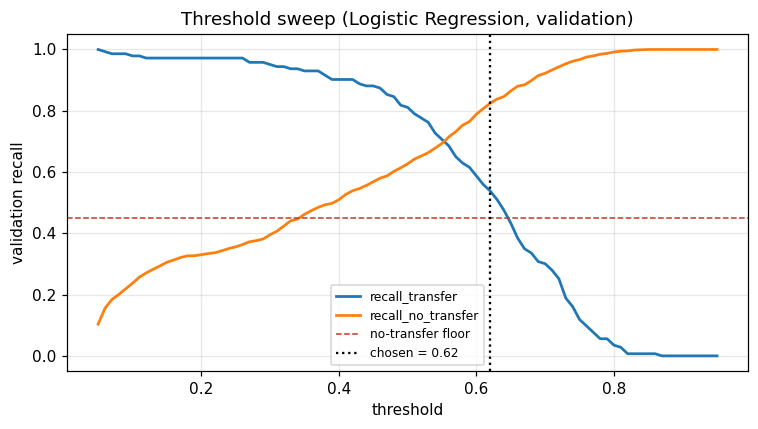

In [12]:
MISS_COST_RATIO = 4
NO_TRANSFER_RECALL_FLOOR = 0.45

final_weights = compute_class_weight("balanced", classes=np.array(sorted(y_train.unique())),
                                     y=y_train)
final_weights = dict(zip(sorted(y_train.unique()), final_weights))
final_model = fit_model(BEST_MODEL, X_train_enc, y_train, params=best_params,
                        weights=final_weights)

proba_val, classes = predict_proba_model(BEST_MODEL, final_model, X_val_enc)
pos_idx = classes.index(PRIMARY_CLASS)
p_val = proba_val[:, pos_idx]
y_val_bin = (y_val == PRIMARY_CLASS).astype(int)

sweep = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (p_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val_bin, pred, labels=[0, 1]).ravel()
    sweep.append({"threshold": t, "recall_transfer": recall_score(y_val_bin, pred, zero_division=0),
                  "recall_no_transfer": recall_score(y_val_bin, pred, pos_label=0, zero_division=0),
                  "expected_cost": (MISS_COST_RATIO * fn + fp) / len(y_val_bin)})
sweep = pd.DataFrame(sweep)

valid = sweep[sweep["recall_no_transfer"] >= NO_TRANSFER_RECALL_FLOOR]
if valid.empty:
    print(f"No threshold kept no-transfer recall >= {NO_TRANSFER_RECALL_FLOOR}.")
    CHOSEN_THRESHOLD = float(sweep.loc[sweep["expected_cost"].idxmin(), "threshold"])
else:
    CHOSEN_THRESHOLD = float(valid.loc[valid["expected_cost"].idxmin(), "threshold"])

print(f"Chosen threshold: {CHOSEN_THRESHOLD:.2f}")
chosen_row = sweep.loc[np.isclose(sweep["threshold"], CHOSEN_THRESHOLD)]
print(chosen_row.to_string(index=False, float_format="%.4f"))

plt.figure(figsize=(7, 4))
for col in ["recall_transfer", "recall_no_transfer"]:
    plt.plot(sweep["threshold"], sweep[col], lw=1.8, label=col)
plt.axhline(NO_TRANSFER_RECALL_FLOOR, color="#c0392b", ls="--", lw=1, label="no-transfer floor")
plt.axvline(CHOSEN_THRESHOLD, color="k", ls=":", lw=1.5, label=f"chosen = {CHOSEN_THRESHOLD:.2f}")
plt.xlabel("threshold"); plt.ylabel("validation recall")
plt.title(f"Threshold sweep ({BEST_MODEL}, validation)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "threshold_sweep.png", bbox_inches="tight"); plt.show()

## 11. Held-out evaluation — opened once

Feature set, model, hyperparameters, and threshold were all chosen on train and validation. The
holdout is read here for the first and only time.

HELD-OUT RESULTS (first and only reading)
              precision    recall  f1-score   support

          no      0.934     0.827     0.877      1093
         yes      0.295     0.552     0.384       143

    accuracy                          0.795      1236
   macro avg      0.614     0.690     0.631      1236
weighted avg      0.860     0.795     0.820      1236

{'roc_auc': 0.7991, 'avg_precision': 0.3257, 'recall_transfer': 0.5524, 'recall_no_transfer': 0.8271, 'precision_transfer': 0.2948}


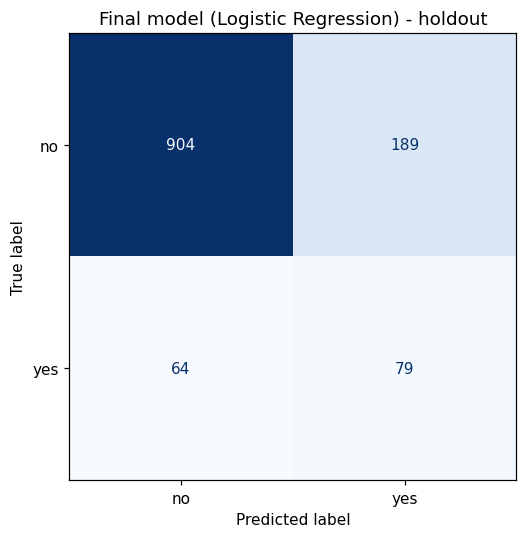

In [13]:
proba_hold, classes = predict_proba_model(BEST_MODEL, final_model, X_hold_enc)
pos_idx = classes.index(PRIMARY_CLASS)
p_hold = proba_hold[:, pos_idx]
y_hold_bin = (y_hold == PRIMARY_CLASS).astype(int)
pred_hold_bin = (p_hold >= CHOSEN_THRESHOLD).astype(int)
y_pred_hold = np.where(pred_hold_bin == 1, PRIMARY_CLASS, "no")

print("=" * 58)
print("HELD-OUT RESULTS (first and only reading)")
print("=" * 58)
print(classification_report(y_hold, y_pred_hold, digits=3))

hold_metrics = {
    "roc_auc": roc_auc_score(y_hold_bin, p_hold),
    "avg_precision": average_precision_score(y_hold_bin, p_hold),
    "recall_transfer": recall_score(y_hold_bin, pred_hold_bin),
    "recall_no_transfer": recall_score(y_hold_bin, pred_hold_bin, pos_label=0),
    "precision_transfer": precision_score(y_hold_bin, pred_hold_bin, zero_division=0),
}
print({k: round(v, 4) for k, v in hold_metrics.items()})

cm = confusion_matrix(y_hold, y_pred_hold, labels=["no", "yes"])
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(ax=ax, colorbar=False, cmap="Blues")
plt.title(f"Final model ({BEST_MODEL}) - holdout"); ax.grid(False)
plt.tight_layout(); plt.savefig(ARTIFACTS / "holdout_confusion.png", bbox_inches="tight"); plt.show()

## 12. What the model pays attention to

Permutation importance on the holdout, not SHAP — consistent across every model in this
project.

                          feature  importance    std
             Collision Force From      0.1797 0.0212
                    Illicit Drugs      0.1741 0.0387
              Alcohol Consumption      0.1385 0.0293
               Road Signals Exist      0.1357 0.0266
              Type of injury No 1      0.0329 0.0143
     Time Taken To Reach Hospital      0.0252 0.0260
               Site of Injury No1      0.0238 0.0105
                        Road Type      0.0182 0.0137
                   Collision With      0.0161 0.0188
              Site of injury No 2      0.0084 0.0075
              Type of Injury No 2      0.0070 0.0083
                              Age      0.0042 0.0193
                        Visiblity      0.0007 0.0066
               Investigation Done     -0.0021 0.0094
                Approximate Speed     -0.0035 0.0064
                   Road Condition     -0.0035 0.0072
                Management Name 1     -0.0042 0.0071
                Management Name 2     -0.0049 

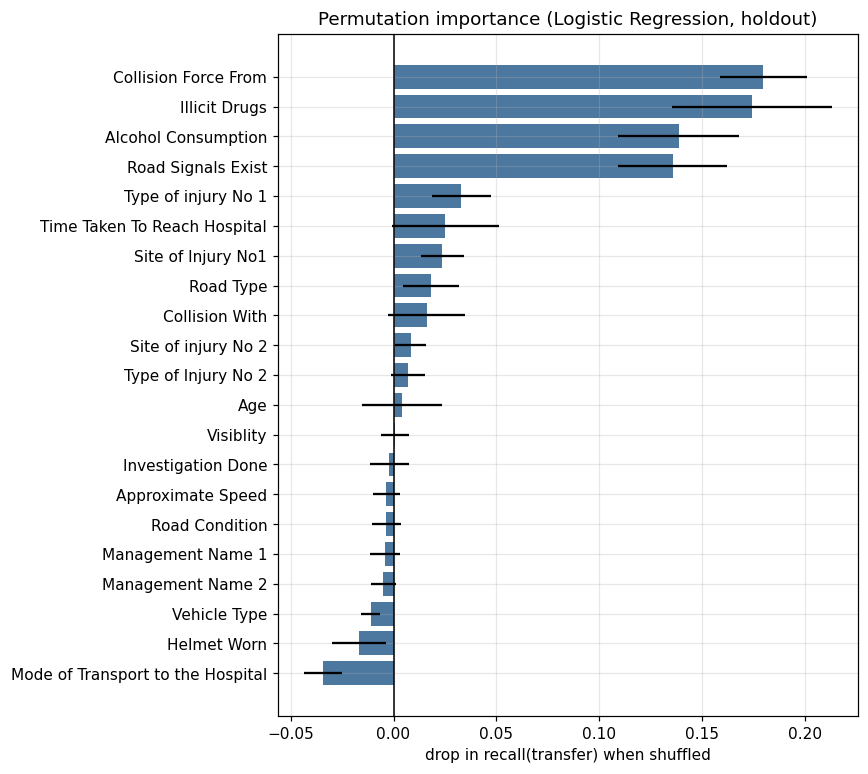

In [14]:
def score_fn(estimator, X, y):
    proba, classes = predict_proba_model(BEST_MODEL, estimator, X)
    pos_idx = classes.index(PRIMARY_CLASS)
    pred = np.where(proba[:, pos_idx] >= CHOSEN_THRESHOLD, PRIMARY_CLASS,
                    [c for c in classes if c != PRIMARY_CLASS][0])
    return recall_transfer(y, pred)


perm = permutation_importance(final_model, X_hold_enc, y_hold, scoring=score_fn,
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)

importance = (pd.DataFrame({"feature": X_hold_enc.columns, "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
print(importance.to_string(index=False, float_format="%.4f"))

plt.figure(figsize=(8, max(4, 0.34 * len(importance))))
top = importance.iloc[::-1]
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#2c5f8d", alpha=0.85)
plt.axvline(0, color="k", lw=1)
plt.xlabel("drop in recall(transfer) when shuffled")
plt.title(f"Permutation importance ({BEST_MODEL}, holdout)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight")
plt.show()

## 13. Confidence layer — derived, not assumed

Completeness floor measured the same way as the other two models: recall(transfer) checked per
completeness level on validation.

In [15]:
MIN_USABLE_RECALL = 0.30

completeness_val = X_val.notna().sum(axis=1) / len(FEATURES)
proba_val2, classes2 = predict_proba_model(BEST_MODEL, final_model, X_val_enc)
pos_idx2 = classes2.index(PRIMARY_CLASS)
p_val2 = proba_val2[:, pos_idx2]
p_val_pred = np.where(p_val2 >= CHOSEN_THRESHOLD, PRIMARY_CLASS,
                      [c for c in classes2 if c != PRIMARY_CLASS][0])

floor_rows = []
for level in sorted(completeness_val.unique()):
    at_level = completeness_val == level
    if at_level.sum() < 20:
        continue
    floor_rows.append({"completeness": level, "patients": int(at_level.sum()),
                       "recall_transfer": recall_transfer(y_val[at_level], p_val_pred[at_level])})

floors = pd.DataFrame(floor_rows).sort_values("completeness")
print(floors.to_string(index=False, float_format="%.3f"))

usable = floors.loc[floors["recall_transfer"] >= MIN_USABLE_RECALL, "completeness"]
COMPLETENESS_FLOOR = float(usable.min()) if not usable.empty else 0.0
print(f"\nCompleteness floor: {COMPLETENESS_FLOOR:.2f} "
      f"({int(np.ceil(COMPLETENESS_FLOOR * len(FEATURES)))} of {len(FEATURES)} fields)")

 completeness  patients  recall_transfer
        0.095        21            0.000
        0.143        35            0.000
        0.190        39            0.000
        0.429        39            0.000
        0.476        59            0.000
        0.571        20            0.000
        0.619        29            1.000
        0.667        57            0.000
        0.714        78            0.000
        0.762        85            0.400
        0.810       109            0.273
        0.857       121            0.480
        0.905       193            0.385
        0.952       200            0.718
        1.000        89            0.724

Completeness floor: 0.62 (13 of 21 fields)


In [16]:
DOCTOR_LABELS = {
    "Age": "age", "Mode of Transport to the Hospital": "how they reached hospital",
    "Time Taken To Reach Hospital": "time taken to reach hospital", "Vehicle Type": "vehicle type",
    "Helmet Worn": "helmet worn", "Collision With": "what they collided with",
    "Approximate Speed": "approximate speed", "Road Type": "road type",
    "Road Condition": "road condition", "Visiblity": "visibility",
    "Road Signals Exist": "road signals present", "Collision Force From": "collision direction",
    "Alcohol Consumption": "alcohol consumption", "Illicit Drugs": "illicit drug use",
    "Site of Injury No1": "main injury site", "Type of injury No 1": "main injury type",
    "Site of injury No 2": "second injury site", "Type of Injury No 2": "second injury type",
    "Investigation Done": "investigation done", "Management Name 1": "primary management given",
    "Management Name 2": "secondary management given",
}


def predict_transfer_probability(record: dict) -> dict:
    present = sum(1 for f in FEATURES if record.get(f) is not None and not pd.isna(record.get(f)))
    completeness = present / len(FEATURES)

    if completeness < COMPLETENESS_FLOOR:
        return {"prediction": None, "probability": None, "completeness": round(completeness, 3),
                "status": f"REFUSED - only {present} of {len(FEATURES)} fields recorded"}

    row = pd.DataFrame([{f: record.get(f) for f in FEATURES}])
    row = encode_ordinal(row, FEATURES)

    proba, classes = predict_proba_model(BEST_MODEL, final_model, row)
    pos_idx = classes.index(PRIMARY_CLASS)
    prob_transfer = float(proba[0, pos_idx])
    prediction = PRIMARY_CLASS if prob_transfer >= CHOSEN_THRESHOLD else "no"

    return {"prediction": prediction, "probability": round(prob_transfer, 3),
            "completeness": round(completeness, 3), "status": "OK"}


print("Example - well-documented record:")
print(predict_transfer_probability(X_hold.iloc[0].to_dict()))
print("\nExample - sparse record:")
print(predict_transfer_probability({"Age": "20-29"}))

Example - well-documented record:
{'prediction': None, 'probability': None, 'completeness': 0.19, 'status': 'REFUSED - only 4 of 21 fields recorded'}

Example - sparse record:
{'prediction': None, 'probability': None, 'completeness': 0.048, 'status': 'REFUSED - only 1 of 21 fields recorded'}


## 14. Save artifacts

In [17]:
joblib.dump(final_model, ARTIFACTS / "transfer_model.joblib")

joblib.dump({"features": FEATURES, "cat_features": CAT_FEATURES, "num_features": NUM_FEATURES,
             "age_order": AGE_ORDER, "time_order": TIME_ORDER, "best_model_name": BEST_MODEL,
             "completeness_floor": COMPLETENESS_FLOOR, "chosen_threshold": CHOSEN_THRESHOLD,
             "rare_maps": {k: list(v) for k, v in rare_maps.items()}},
            ARTIFACTS / "transfer_metadata.joblib")

summary = {
    "purpose": "Post-treatment prediction of transfer likelihood, intended for doctor use.",
    "split": {"train": len(y_train), "validation": len(y_val), "holdout": len(y_hold),
              "protocol": "all decisions on train/validation; holdout read once"},
    "target": {"classes": ["no", "yes"], "prevalence": y_all.value_counts(normalize=True).round(4).to_dict()},
    "eligibility_audit": audit.value_counts().to_dict(),
    "features": {"candidates": len(CANDIDATE_FEATURES), "final": FEATURES, "dropped": DROPPED},
    "model_comparison": results.to_dict(orient="records"),
    "model": {"family": BEST_MODEL, "best_params": {k: str(v) for k, v in best_params.items()},
              "miss_cost_ratio": MISS_COST_RATIO, "chosen_threshold": CHOSEN_THRESHOLD,
              "no_transfer_recall_floor": NO_TRANSFER_RECALL_FLOOR},
    "holdout_metrics": {k: round(float(v), 4) for k, v in hold_metrics.items()},
    "completeness_floor": round(COMPLETENESS_FLOOR, 3),
    "top_features": importance.head(8)["feature"].tolist(),
}
with open(ARTIFACTS / "model_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

screening.to_csv(ARTIFACTS / "feature_screening.csv", index=False)
importance.to_csv(ARTIFACTS / "permutation_importance.csv", index=False)
results.to_csv(ARTIFACTS / "model_comparison.csv", index=False)

print(json.dumps(summary, indent=2))
print(f"\nSaved to {ARTIFACTS.resolve()}")

{
  "purpose": "Post-treatment prediction of transfer likelihood, intended for doctor use.",
  "split": {
    "train": 3706,
    "validation": 1236,
    "holdout": 1236,
    "protocol": "all decisions on train/validation; holdout read once"
  },
  "target": {
    "classes": [
      "no",
      "yes"
    ],
    "prevalence": {
      "no": 0.8843,
      "yes": 0.1157
    }
  },
  "eligibility_audit": {
    "BOOKKEEPING": 65,
    "POST_ARRIVAL_ELIGIBLE": 37,
    "EXCLUDED_ETHICAL": 16,
    "TARGET_ADJACENT": 7,
    "ADMIN": 4,
    "TARGET_INPUT": 1
  },
  "features": {
    "candidates": 21,
    "final": [
      "Age",
      "Mode of Transport to the Hospital",
      "Time Taken To Reach Hospital",
      "Vehicle Type",
      "Helmet Worn",
      "Collision With",
      "Approximate Speed",
      "Road Type",
      "Road Condition",
      "Visiblity",
      "Road Signals Exist",
      "Collision Force From",
      "Alcohol Consumption",
      "Illicit Drugs",
      "Site of Injury No1",
  

## 15. Limitations

**1. Rare-event classification limits the ceiling.** 11.6% prevalence — more balanced than
discharge outcome's or stay duration's rarest class, but still a real constraint.

**2. This is a screening aid; the doctor's judgement governs.** A flagged transfer risk means
"worth a second look," not "must transfer."

**3. `MISS_COST_RATIO` (4) and `NO_TRANSFER_RECALL_FLOOR` (0.45) are judgement calls**,
sensitivity-tested against the threshold sweep in Section 10, tunable by an adopting hospital.

**4. `Treatment During Tranfer`, `State of Transfer`, and length-of-stay were excluded on
confirmed leakage/confound grounds** (Section 3a), not merely suspected ones — the strongest
exclusion justification of the three post-treatment models in this project.

**5. Single-setting data.** One hospital network, northern Sri Lanka.

**6. Not validated prospectively.** Retrospective evaluation only.